# DS201 · Lab 2 · CNN với PyTorch


## 0. Thiết lập

In [1]:
# Import thư viện và cố định seed
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.11.0+cu128
device : cuda


In [8]:
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

# Phần I · Từ ảnh đến feature map

## 1. Biểu diễn ảnh dưới dạng tensor

Hai quy ước: `H × W × C` khi vẽ sơ đồ, `N × C × H × W` khi làm việc với tensor
PyTorch.

In [9]:
# Tạo tensor cho một ảnh màu và cho một batch ảnh
anh = torch.rand(3, 224, 224)
batch = torch.rand(32, 3, 224, 224)

show("một ảnh (C, H, W)", anh)
show("một batch (N, C, H, W)", batch)

print()
print("N =", batch.shape[0], " C =", batch.shape[1],
      " H =", batch.shape[2], " W =", batch.shape[3])

# Nhận xét: công thức output size và số tham số không phụ thuộc N

một ảnh (C, H, W)            (3, 224, 224)
một batch (N, C, H, W)       (32, 3, 224, 224)

N = 32  C = 3  H = 224  W = 224


## 2. Chi phí tham số khi dùng MLP cho ảnh

In [10]:
# Đếm tham số của một lớp fully connected 1000 neuron trên hai cỡ ảnh
for h, w in [(256, 256), (224, 224)]:
    n_in = h * w * 3          # TODO
    n_hidden = 1000
    params = n_in * n_hidden        # TODO: bỏ qua bias
    print(f"{h}x{w}x3 -> {n_in:>8,} input x {n_hidden:,} neuron = {params:>14,} tham số")

assert 256 * 256 * 3 * 1000 == 196_608_000
assert 224 * 224 * 3 * 1000 == 150_528_000

256x256x3 ->  196,608 input x 1,000 neuron =    196,608,000 tham số
224x224x3 ->  150,528 input x 1,000 neuron =    150,528,000 tham số


In [11]:
# Đối chiếu với một nn.Linear thật
fc = nn.Linear(224 * 224 * 3, 1000, bias=False)  # TODO
print("nn.Linear(150528, 1000, bias=False):", f"{n_params(fc):,} tham số")
assert n_params(fc) == 150_528_000

nn.Linear(150528, 1000, bias=False): 150,528,000 tham số


## 3. Flatten làm mất cấu trúc không gian

Hoán vị ngẫu nhiên thứ tự pixel: tập giá trị không đổi nên MLP không phân biệt
được, còn quan hệ lân cận mà conv cần thì đã mất.

In [12]:
# Tạo ảnh 3x3, flatten rồi hoán vị thứ tự pixel
x = torch.arange(1., 10.).reshape(1, 1, 3, 3)
flat = x.flatten(start_dim=1)  # TODO
perm = torch.randperm(flat.shape[1])
flat_perm = flat[:, perm]  # TODO

print("ảnh gốc 3x3:\n", x[0, 0])
print("\nsau flatten     :", flat[0].tolist())
print("sau khi hoán vị :", flat_perm[0].tolist())

ảnh gốc 3x3:
 tensor([[1., 2., 3.],
        [4., 5., 6.],
        [7., 8., 9.]])

sau flatten     : [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]
sau khi hoán vị : [2.0, 4.0, 5.0, 7.0, 9.0, 6.0, 8.0, 3.0, 1.0]


In [13]:
# So sánh: tổng và tập giá trị không đổi sau hoán vị
print("tổng giá trị giống nhau:", torch.allclose(flat.sum(), flat_perm.sum()))
print("tập giá trị giống nhau :",
      sorted(flat[0].tolist()) == sorted(flat_perm[0].tolist()))

# Nhận xét: với nn.Linear hai vector chỉ khác thứ tự input, mạng học lại được;
# với conv thì quan hệ lân cận đã bị phá

tổng giá trị giống nhau: True
tập giá trị giống nhau : True


## 4. Phép tích chập

In [14]:
# Tạo ảnh đầu vào 6x6 và một kernel phát hiện cạnh dọc
anh = torch.tensor([[4., 9., 2., 5., 8., 3.],
                    [5., 6., 2., 4., 0., 3.],
                    [2., 4., 5., 4., 5., 2.],
                    [5., 6., 5., 4., 7., 8.],
                    [5., 7., 7., 9., 2., 1.],
                    [5., 8., 5., 3., 8., 4.]]).reshape(1, 1, 6, 6)

kernel = torch.tensor([[1., 0., -1.],
                       [1., 0., -1.],
                       [1., 0., -1.]]).reshape(1, 1, 3, 3)

show("ảnh vào", anh)
show("kernel", kernel)

ảnh vào                      (1, 1, 6, 6)
kernel                       (1, 1, 3, 3)


In [15]:
# Tích chập stride 1, không padding
out = F.conv2d(anh, kernel)  # TODO

show("output", out)
print("\noutput:\n", out[0, 0])
print("\nô đầu tiên =", out[0, 0, 0, 0].item())
print("ô thứ hai  =", out[0, 0, 0, 1].item())

assert out.shape == (1, 1, 4, 4)
assert out[0, 0, 0, 0].item() == 2.0
assert out[0, 0, 0, 1].item() == 6.0

output                       (1, 1, 4, 4)

output:
 tensor([[ 2.,  6., -4.,  5.],
        [ 0.,  4.,  0., -1.],
        [-5.,  0.,  3.,  6.],
        [-2.,  5.,  0.,  3.]])

ô đầu tiên = 2.0
ô thứ hai  = 6.0


In [16]:
# Ba vùng ảnh để thấy filter này phản ứng với cạnh dọc
cases = {
    "trái sáng, phải tối": [[9., 9., 0.], [9., 9., 0.], [9., 9., 0.]],
    "trái tối, phải sáng": [[0., 9., 9.], [0., 9., 9.], [0., 9., 9.]],
    "hai bên như nhau   ": [[5., 5., 5.], [5., 5., 5.], [5., 5., 5.]],
}
for name, patch in cases.items():
    v = F.conv2d(torch.tensor(patch).reshape(1, 1, 3, 3), kernel).item()
    print(f"{name} -> {v:>7.1f}")

# Nhận xét: cùng dấu thì cạnh sáng-tối, trái dấu thì tối-sáng, bằng 0 thì phẳng

trái sáng, phải tối ->    27.0
trái tối, phải sáng ->   -27.0
hai bên như nhau    ->     0.0


In [17]:
# Trong CNN, 9 trọng số này không viết tay mà học bằng backpropagation
conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
print("conv.weight.requires_grad =", conv.weight.requires_grad)

conv.weight.requires_grad = True


## 5. Weight sharing

Cùng bài toán `64×64×3 → 64×64×16`, so sánh fully connected với conv.

In [18]:
# Khởi tạo hai cách cho cùng một bài toán
n_in, n_out = 64 * 64 * 3, 64 * 64 * 16

mlp = nn.Linear(n_in, n_out, bias=False)  # TODO
cnv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)  # TODO

print(f"MLP  : {n_in:,} x {n_out:,} = {n_params(mlp):>14,} tham số")
print(f"Conv : (3x3x3 + 1) x 16      = {n_params(cnv):>14,} tham số")
print(f"\nchênh {n_params(mlp) / n_params(cnv):,.0f} lần")

assert n_params(mlp) == 805_306_368
assert n_params(cnv) == 448

MLP  : 12,288 x 65,536 =    805,306,368 tham số
Conv : (3x3x3 + 1) x 16      =            448 tham số

chênh 1,797,559 lần


In [19]:
# Số tham số của conv không phụ thuộc kích thước ảnh
for size in (28, 64, 512):
    y = cnv(torch.rand(1, 3, size, size))
    print(f"ảnh {size:>3}x{size:<3} -> output {tuple(y.shape)}, vẫn {n_params(cnv)} tham số")

ảnh  28x28  -> output (1, 16, 28, 28), vẫn 448 tham số
ảnh  64x64  -> output (1, 16, 64, 64), vẫn 448 tham số
ảnh 512x512 -> output (1, 16, 512, 512), vẫn 448 tham số


### Equivariance chỉ đúng với phép tịnh tiến

Dịch ảnh 8 pixel thì feature map dịch đúng 8 pixel; xoay 90° thì không.

In [21]:
# Tạo ảnh có một ô vuông sáng, kernel trung bình 3x3 và hàm tìm vị trí đỉnh
img = torch.zeros(1, 1, 32, 32)
img[0, 0, 10:14, 10:14] = 1.0
w = torch.ones(1, 1, 3, 3) / 9.0


def peak(t):
    idx = t.flatten().argmax().item()
    return divmod(idx, t.shape[-1])

In [22]:
# So sánh vị trí đỉnh của feature map khi dịch và khi xoay ảnh
y0 = F.conv2d(img, w, padding=1)
y1 = F.conv2d(torch.roll(img, shifts=8, dims=3), w, padding=1)  # TODO: dịch ảnh 8 pixel theo chiều ngang
y2 = F.conv2d(torch.rot90(img, k=1, dims=(2, 3)), w, padding=1)  # TODO: xoay ảnh 90 độ

print("ảnh gốc      :", peak(y0[0, 0]))
print("dịch 8 pixel :", peak(y1[0, 0]), "-> dịch theo đúng 8")
print("xoay 90 độ   :", peak(y2[0, 0]), "-> không suy ra được từ ảnh gốc")

# Nhận xét: xoay, co giãn và đổi sáng phải dạy bằng data augmentation

ảnh gốc      : (11, 11)
dịch 8 pixel : (11, 19) -> dịch theo đúng 8
xoay 90 độ   : (19, 11) -> không suy ra được từ ảnh gốc


## 6. Tích chập trên input nhiều channel

Một filter cho ra đúng một feature map, bất kể input có bao nhiêu channel.

In [23]:
# Một filter so với nhiều filter trên cùng input 3 channel
x = torch.rand(1, 3, 6, 6)
one = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3)  # TODO
many = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)  # TODO

show("input", x)
show("1 filter  -> output", one(x))
show("16 filter -> output", many(x))

print()
print("filter 3x3 trên 3 channel:", n_params(one), "tham số = 3*3*3 + 1")
print("out_channels = số filter :", many(x).shape[1])

assert one(x).shape[1] == 1
assert n_params(one) == 3 * 3 * 3 + 1
assert many(x).shape[1] == 16

input                        (1, 3, 6, 6)
1 filter  -> output          (1, 1, 4, 4)
16 filter -> output          (1, 16, 4, 4)

filter 3x3 trên 3 channel: 28 tham số = 3*3*3 + 1
out_channels = số filter : 16


In [24]:
# Cùng kernel 3x3 nhưng input 64 channel
q = nn.Conv2d(in_channels=64, out_channels=1, kernel_size=3)  # TODO
print("filter 3x3 trên 64 channel:", n_params(q), "tham số = 3*3*64 + 1, vẫn ra 1 channel")
assert n_params(q) == 3 * 3 * 64 + 1

filter 3x3 trên 64 channel: 577 tham số = 3*3*64 + 1, vẫn ra 1 channel


## 7. Công thức output size

$$O = \left\lfloor \frac{I + 2P - K}{S} \right\rfloor + 1$$

In [28]:
# Cài công thức output size (có thêm dilation D)
def out_size(I, K, S, P, D=1):
    return (I + 2 * P - D * (K - 1) - 1) // S + 1  # TODO

In [29]:
# Đối chiếu công thức với kết quả thật của nn.Conv2d
vi_du = [(6, 3, 1, 0, 4), (6, 3, 2, 0, 2), (6, 3, 2, 1, 3), (64, 3, 1, 1, 64)]

print(f"{'#':<3}{'I':>5}{'K':>4}{'S':>4}{'P':>4}{'O (công thức)':>16}{'O (PyTorch)':>14}")
for i, (I, K, S, P, expect) in enumerate(vi_du, 1):
    o = out_size(I, K, S, P)
    real = nn.Conv2d(1, 1, K, stride=S, padding=P)(torch.rand(1, 1, I, I)).shape[-1]
    print(f"{i:<3}{I:>5}{K:>4}{S:>4}{P:>4}{o:>16}{real:>14}")
    assert o == expect == real

# Nhận xét: phép chia lấy phần nguyên, ví dụ 2 cho (6-3)/2 = 1.5 -> 1 -> O = 2
print("\nP = (K-1)/2 giữ nguyên kích thước ->", {k: (k - 1) // 2 for k in (3, 5, 7)})

#      I   K   S   P   O (công thức)   O (PyTorch)
1      6   3   1   0               4             4
2      6   3   2   0               2             2
3      6   3   2   1               3             3
4     64   3   1   1              64            64

P = (K-1)/2 giữ nguyên kích thước -> {3: 1, 5: 2, 7: 3}


In [30]:
# Ảnh hưởng của stride và padding trên cùng ảnh 28x28
x = torch.rand(1, 1, 28, 28)
for S, P in [(1, 0), (2, 0), (2, 1), (1, 1)]:
    y = nn.Conv2d(1, 1, 3, stride=S, padding=P)(x)
    print(f"stride={S}, padding={P} -> {tuple(y.shape)}   công thức: {out_size(28, 3, S, P)}")

stride=1, padding=0 -> (1, 1, 26, 26)   công thức: 26
stride=2, padding=0 -> (1, 1, 13, 13)   công thức: 13
stride=2, padding=1 -> (1, 1, 14, 14)   công thức: 14
stride=1, padding=1 -> (1, 1, 28, 28)   công thức: 28


In [31]:
# Đối chiếu cách khai báo padding của PyTorch (số) và Keras (chuỗi)
print("Keras 'valid', S=2 -> 13 | PyTorch P=0:", out_size(28, 3, 2, 0))
print("Keras 'same',  S=2 -> 14 | ceil(28/2) :", math.ceil(28 / 2))
assert out_size(28, 3, 2, 0) == 13

Keras 'valid', S=2 -> 13 | PyTorch P=0: 13
Keras 'same',  S=2 -> 14 | ceil(28/2) : 14


## 8. Pooling

Pooling không có tham số và không đổi số channel.

In [32]:
# Khởi tạo feature map và hai lớp pooling
fm = torch.rand(1, 64, 16, 16)
mp = nn.MaxPool2d(kernel_size=2, stride=2)  # TODO
ap = nn.AvgPool2d(kernel_size=2, stride=2)  # TODO

show("feature map vào", fm)
show("sau MaxPool 2x2", mp(fm))
show("sau AvgPool 2x2", ap(fm))

print("\nsố tham số của MaxPool2d(2,2):", n_params(mp))
print("số channel trước/sau         :", fm.shape[1], "->", mp(fm).shape[1])

assert n_params(mp) == 0
assert mp(fm).shape == (1, 64, 8, 8)

feature map vào              (1, 64, 16, 16)
sau MaxPool 2x2              (1, 64, 8, 8)
sau AvgPool 2x2              (1, 64, 8, 8)

số tham số của MaxPool2d(2,2): 0
số channel trước/sau         : 64 -> 64


In [33]:
# Kiểm tra trên một ô 2x2 cụ thể
patch = torch.tensor([[3., 2.], [0., 7.]]).reshape(1, 1, 2, 2)
print("max(3,2,0,7) =", F.max_pool2d(patch, 2).item(),
      " avg =", F.avg_pool2d(patch, 2).item())
assert F.max_pool2d(patch, 2).item() == 7.0
assert F.avg_pool2d(patch, 2).item() == 3.0

max(3,2,0,7) = 7.0  avg = 3.0


## 9. Receptive field tăng theo độ sâu

Đo bằng gradient: một neuron ở output phụ thuộc bao nhiêu pixel input.

In [35]:
# Hàm đo receptive field bằng gradient của một neuron ở tâm output
def receptive_field(n_layers, k=3, size=31):
    x = torch.zeros(1, 1, size, size, requires_grad=True)
    y = x
    for _ in range(n_layers):
        y = F.conv2d(y, w, padding=k // 2)  # TODO: conv kernel kxk toàn số 1, giữ nguyên kích thước
    y[0, 0, size // 2, size // 2].backward()
    touched = (x.grad[0, 0] != 0)
    rows = touched.any(dim=1).nonzero()
    return int(rows.max() - rows.min() + 1)

In [36]:
# Receptive field sau 1, 2, 3 layer conv 3x3
for n in (1, 2, 3):
    rf = receptive_field(n)
    print(f"sau {n} layer conv 3x3 -> receptive field {rf}x{rf}")
    assert rf == 2 * n + 1

sau 1 layer conv 3x3 -> receptive field 3x3
sau 2 layer conv 3x3 -> receptive field 5x5
sau 3 layer conv 3x3 -> receptive field 7x7


In [37]:
# Vì sao VGG chỉ dùng 3x3: cùng vùng nhìn 5x5 nhưng rẻ hơn và nhiều phi tuyến hơn
C = 64
print(f"một layer 5x5 : 25*C^2 = {25 * C * C:>9,} tham số, 1 activation")
print(f"hai layer 3x3 : 18*C^2 = {18 * C * C:>9,} tham số, 2 activation")

một layer 5x5 : 25*C^2 =   102,400 tham số, 1 activation
hai layer 3x3 : 18*C^2 =    73,728 tham số, 2 activation


## 10. Biến đổi shape qua một CNN hoàn chỉnh

`39×39×3` đi đến `7×7×40`, flatten thành 1.960 chiều.

In [43]:
# Khởi tạo mạng ba conv layer
cnn = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, stride=1),  # TODO: 39 -> 37
    nn.ReLU(),
    nn.Conv2d(16, 32, kernel_size=5, stride=2),  # TODO: 37 -> 17
    nn.ReLU(),
    nn.Conv2d(32, 40, kernel_size=5, stride=2),  # TODO: 17 ->  7
    nn.ReLU(),
)

In [44]:
# Theo dõi shape qua từng conv layer
x = torch.rand(1, 3, 39, 39)

print(f"{'layer':<10}{'output shape':<22}{'tham số kernel'}")
print(f"{'input':<10}{str(tuple(x.shape)):<22}")
for layer in cnn:
    x = layer(x)
    if isinstance(layer, nn.Conv2d):
        print(f"{'conv':<10}{str(tuple(x.shape)):<22}"
              f"K={layer.kernel_size[0]} S={layer.stride[0]} P={layer.padding[0]}")

flat = x.flatten(1)
show("sau flatten", flat)

assert tuple(x.shape) == (1, 40, 7, 7)
assert flat.shape[1] == 1960

# Nhận xét: chiều không gian giảm dần, số channel tăng dần

layer     output shape          tham số kernel
input     (1, 3, 39, 39)        
conv      (1, 16, 37, 37)       K=3 S=1 P=0
conv      (1, 32, 17, 17)       K=5 S=2 P=0
conv      (1, 40, 7, 7)         K=5 S=2 P=0
sau flatten                  (1, 1960)


## 11. Số chiều đầu vào của nn.Linear

Ô dưới cố ý gây lỗi: con số bên trái trong thông báo lỗi chính là số chiều phải
điền.

In [45]:
# Tạo feature map rồi flatten, sau đó đưa vào một Linear khai báo sai số chiều
feat = torch.rand(64, 16, 13, 13)
flat = feat.flatten(1)
print("số chiều thật sau flatten:", flat.shape[1])

sai = nn.Linear(512, 21)
try:
    sai(flat)
except RuntimeError as e:
    print("\nRuntimeError:\n ", e)

số chiều thật sau flatten: 2704

RuntimeError:
  mat1 and mat2 shapes cannot be multiplied (64x2704 and 512x21)


In [46]:
# Khai báo đúng số chiều
dung = nn.Linear(flat.shape[1], 21)  # TODO
print(f"nn.Linear({flat.shape[1]}, 21) -> output", tuple(dung(flat).shape))
assert flat.shape[1] == 2704

nn.Linear(2704, 21) -> output (64, 21)


## 12. Câu hỏi tự kiểm tra

In [47]:
# 1. Input [32, 3, 64, 64] qua nn.Conv2d(3, 16, kernel_size=5, stride=1, padding=2)
# 2. Conv layer đó có bao nhiêu tham số
conv = nn.Conv2d(3, 16, kernel_size=5, stride=1, padding=2)  # TODO
y = conv(torch.rand(32, 3, 64, 64))

print("1.", tuple(y.shape))
print("2.", f"{n_params(conv):,}", "= (5*5*3 + 1) * 16")
assert tuple(y.shape) == (32, 16, 64, 64)
assert n_params(conv) == 1216

1. (32, 16, 64, 64)
2. 1,216 = (5*5*3 + 1) * 16


In [48]:
# 3. Filter 3x3 trên input 64 channel
# 4. MaxPool2d(2, 2) có bao nhiêu tham số
c = nn.Conv2d(64, 1, kernel_size=3)  # TODO
print("3.", n_params(c), "tham số, cho ra", c(torch.rand(1, 64, 8, 8)).shape[1], "channel")
print("4.", n_params(nn.MaxPool2d(2, 2)), "tham số")

3. 577 tham số, cho ra 1 channel
4. 0 tham số


# Phần II · CNN cơ bản và LeNet-5

## 13. Pipeline dữ liệu

Các ô dưới cần bộ dữ liệu VinaFood21. Nếu chưa có, chúng tự bỏ qua và phần còn
lại của notebook vẫn chạy được.

In [50]:
# Cấu hình chung cho cả bốn bài: đường dẫn, kích thước ảnh, batch size, seed (Kaggle)
from pathlib import Path
import zipfile

KAGGLE_INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")

IMG_SIZE = 64
BATCH = 32
SEED = 42


def find_root(base):
    """Trả về thư mục cha của thư mục 'train' đầu tiên tìm thấy dưới base."""
    for p in sorted(base.rglob("train")):
        if p.is_dir():
            return p.parent
    return None


def locate_dataset():
    cands = [d for d in KAGGLE_INPUT.iterdir() if "vinafood21" in d.name.lower()]
    cands = cands or [KAGGLE_INPUT]

    for d in cands:
        root = find_root(d)
        if root is not None:
            return root

    for d in cands:
        for z in d.rglob("VinaFood21.zip"):
            out = WORK / "VinaFood21_extracted"
            if not out.exists():
                print("Đang giải nén", z, "->", out)
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(out)
            root = find_root(out)
            if root is not None:
                return root
    return None


DATA_ROOT = locate_dataset() or (KAGGLE_INPUT / "vinafood21")
HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

Tìm thấy dữ liệu: True - /kaggle/input/datasets/ttrinh1805/vinafood21/VinaFood21


In [51]:
# Kiểm tra torchvision và chốt mean/std của ImageNet
from torch.utils.data import DataLoader

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

try:
    from torchvision import datasets, transforms
    HAS_TV = True
except ImportError:
    HAS_TV = False
    print("Chưa có torchvision.")

READY = HAS_DATA and HAS_TV
print("Sẵn sàng nạp dữ liệu:", READY)

Sẵn sàng nạp dữ liệu: True


In [52]:
# Hai bộ transform riêng: train có augment, val/test không
if HAS_TV:
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
  # TODO
    print("Đã dựng train_tf và eval_tf.")

Đã dựng train_tf và eval_tf.


In [60]:
# Tạo dataset và DataLoader: tách 10% từ train làm val (không dùng test)
import torch
from torch.utils.data import DataLoader, Subset

CLASSES = [f"lop_{i}" for i in range(21)]
train_ds = val_ds = train_dl = val_dl = None

if READY:
    full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)  # có augmentation
    full_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)    # không augmentation

    g = torch.Generator().manual_seed(SEED)
    idx = torch.randperm(len(full_train), generator=g).tolist()
    n_val = int(0.1 * len(idx))
    train_idx, val_idx = idx[n_val:], idx[:n_val]

    train_ds = Subset(full_train, train_idx)
    val_ds = Subset(full_eval, val_idx)

    # Subset không có các thuộc tính này, gán lại để code phía sau dùng được
    for ds, ids in ((train_ds, train_idx), (val_ds, val_idx)):
        ds.classes = full_train.classes
        ds.class_to_idx = full_train.class_to_idx
        ds.targets = [full_train.targets[i] for i in ids]

    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_dl = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)

    CLASSES = full_train.classes
    print("số lớp      :", len(CLASSES))
    print("số ảnh train:", len(train_ds))
    print("số ảnh val  :", len(val_ds))
    print("thứ tự lớp  :", CLASSES[:5], "...")
else:
    print("Bỏ qua phần load dữ liệu.")

số lớp      : 21
số ảnh train: 9040
số ảnh val  : 1004
thứ tự lớp  : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...


In [61]:
# Chiều tensor trước và sau DataLoader: một ảnh so với một batch
if READY:
    anh, nhan = train_ds[0]
    xb, yb = next(iter(train_dl))
    show("một ảnh sau transform", anh)
    show("một batch vào model", xb)
    show("nhãn", yb)
else:
    show("một ảnh sau transform", torch.rand(3, IMG_SIZE, IMG_SIZE))
    show("một batch vào model", torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE))
    print("(tensor giả lập, vì chưa có dữ liệu thật)")

một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)


## 14. LeNet-5

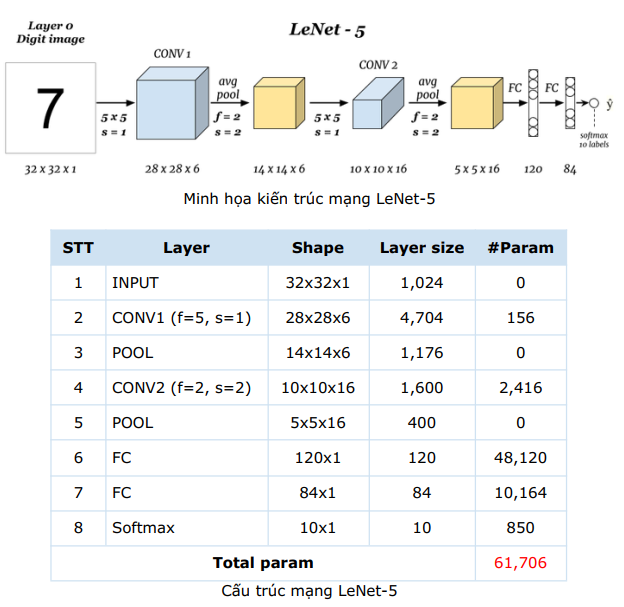

Bản gốc 1998 nhận ảnh xám `32×32×1` và 10 lớp; bản dùng cho Bài 1 nhận ảnh màu
`64×64×3` và 21 lớp. Hai cấu hình khác nhau về số tham số nên tham số hoá cho rõ.

In [65]:
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)  # TODO
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)  # TODO
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)  # TODO
        self.f6 = nn.Linear(120, 84)  # TODO
        self.out = nn.Linear(84, num_classes)  # TODO
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        # TODO
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


In [66]:
# Khởi tạo cấu hình của Bài 1: ảnh 64x64x3, 21 lớp
lenet = LeNet5(in_ch=3, img=64, num_classes=21)
print("số chiều sau flatten:", lenet.n_flat)
print("tổng tham số        :", f"{n_params(lenet):,}")

assert lenet.n_flat == 2704
assert n_params(lenet) == 339_421

số chiều sau flatten: 2704
tổng tham số        : 339,421


In [68]:
# Hàm dựng bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total

In [69]:
# In bảng cho cấu hình ảnh 64x64
rows, total = layer_table(lenet, 64)

print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")
assert total == 339_421

# Nhận xét: tham số dồn gần hết vào F5, hai conv layer rất nhẹ

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


### Ảnh hưởng của kích thước ảnh đầu vào

Cùng kiến trúc, chỉ đổi kích thước ảnh. Toàn bộ chênh lệch nằm ở `F5`.

In [70]:
# So sánh cấu hình ảnh 32x32 và 64x64
print(f"{'resize':<10}{'sau S4':<14}{'flatten':>9}{'F5':>12}{'tổng':>12}{'conv %':>9}")
for img in (32, 64):
    m = LeNet5(in_ch=3, img=img, num_classes=21)
    conv_p = n_params(m.c1) + n_params(m.c3)
    side = int((m.n_flat // 16) ** 0.5)
    print(f"{img}x{img:<5}{f'{side}x{side}x16':<14}{m.n_flat:>9,}"
          f"{n_params(m.f5):>12,}{n_params(m):>12,}"
          f"{100 * conv_p / n_params(m):>8.2f}%")

resize    sau S4          flatten          F5        tổng   conv %
32x32   5x5x16              400      48,120      62,941    4.56%
64x64   13x13x16          2,704     324,600     339,421    0.85%


In [71]:
# Kiểm tra: phần conv giữ nguyên, chỉ phần fully connected phình ra
m32, m64 = LeNet5(img=32), LeNet5(img=64)

assert n_params(m32) == 62_941 and n_params(m64) == 339_421
assert n_params(m32.c1) + n_params(m32.c3) == 2872
assert n_params(m64.c1) + n_params(m64.c3) == 2872

print(f"Tổng tham số gấp {n_params(m64) / n_params(m32):.2f} lần,"
      " hai conv layer vẫn 2,872.")

Tổng tham số gấp 5.39 lần, hai conv layer vẫn 2,872.


## 15. Dropout, BatchNorm và chế độ train/eval

Quên `model.eval()` là lỗi im lặng hay gặp nhất.

In [72]:
# BatchNorm2d có 2 tham số học được cho mỗi channel (gamma, beta)
bn = nn.BatchNorm2d(64)
print("BatchNorm2d(64):", n_params(bn), "tham số = 2 * 64")
assert n_params(bn) == 128

BatchNorm2d(64): 128 tham số = 2 * 64


In [75]:
# Dropout cho kết quả khác nhau ở train và giống nhau ở eval
net = nn.Sequential(nn.Linear(10, 10), nn.Dropout(p=0.5))
x = torch.ones(4, 10)

# TODO: chuyển sang chế độ train
net.train()
a, b = net(x), net(x)
print("model.train(): hai lần forward giống nhau?", torch.equal(a, b))

# TODO: chuyển sang chế độ eval
net.eval()
a, b = net(x), net(x)
print("model.eval() : hai lần forward giống nhau?", torch.equal(a, b))

# Nhận xét: quên eval() thì mỗi lần đánh giá ra một con số khác mà không báo lỗi

model.train(): hai lần forward giống nhau? False
model.eval() : hai lần forward giống nhau? True


In [76]:
# Chạy thử đúng một batch qua LeNet trước khi huấn luyện cả epoch
xb = next(iter(train_dl))[0] if READY else torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE)

# TODO: chế độ eval, không tính gradient
lenet.eval()
with torch.no_grad():
    logits = lenet(xb)


show("input", xb)
show("logits", logits)
assert logits.shape == (xb.shape[0], 21)

input                        (32, 3, 64, 64)
logits                       (32, 21)


# Phần III · Inception

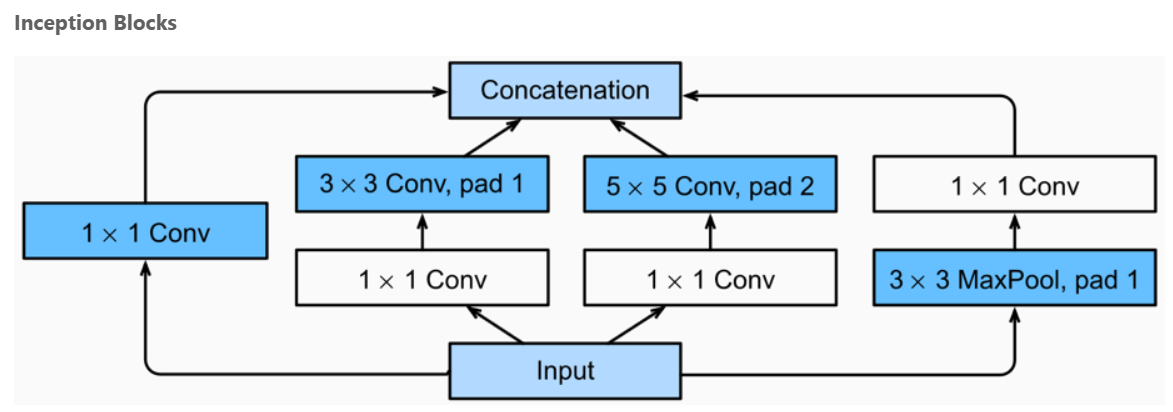

## 16. Inception block: bốn nhánh song song

Bộ sáu tham số là `(f1, f3r, f3, f5r, f5, fp)`. `f3r` và `f5r` là channel trung
gian, không cộng vào output.

In [77]:
# Định nghĩa Inception block
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)


In [78]:
# Khởi tạo block đầu và xem shape ra của từng nhánh
blk1 = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
x = torch.rand(1, 1, 28, 28)

print("shape ra của từng nhánh:")
for name, br in [("1x1", blk1.b1), ("1x1->3x3", blk1.b2),
                 ("1x1->5x5", blk1.b3), ("pool->1x1", blk1.b4)]:
    show("  " + name, br(x))

show("sau concat", blk1(x))
print("\nsố channel ra = 16 + 24 + 8 + 8 =", blk1(x).shape[1])
print("tham số block 1:", f"{n_params(blk1):,}")

assert blk1(x).shape == (1, 56, 28, 28)
assert n_params(blk1) == 4376

shape ra của từng nhánh:
  1x1                        (1, 16, 28, 28)
  1x1->3x3                   (1, 24, 28, 28)
  1x1->5x5                   (1, 8, 28, 28)
  pool->1x1                  (1, 8, 28, 28)
sau concat                   (1, 56, 28, 28)

số channel ra = 16 + 24 + 8 + 8 = 56
tham số block 1: 4,376


In [79]:
# Điều kiện để nối được: H và W của mọi nhánh phải khớp
a = torch.rand(1, 16, 28, 28)
b = torch.rand(1, 24, 14, 14)      # nhánh lỡ dùng stride 2
try:
    torch.cat([a, b], dim=1)
except RuntimeError as e:
    print("RuntimeError:\n ", e)

# Nhận xét: vì thế mọi nhánh đều stride 1 và padding giữ nguyên kích thước

RuntimeError:
  Sizes of tensors must match except in dimension 1. Expected size 28 but got size 14 for tensor number 1 in the list.


In [80]:
# Block thứ hai, đặt trên input 56 channel
blk2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
y = blk2(torch.rand(1, 56, 14, 14))

print("channel ra     :", y.shape[1], "= 32 + 48 + 16 + 16")
print("tham số block 2:", f"{n_params(blk2):,}")

assert y.shape[1] == 112
assert n_params(blk2) == 22_104

channel ra     : 112 = 32 + 48 + 16 + 16
tham số block 2: 22,104


## 17. Concatenate so với phép cộng tensor

Hai cách gộp nhánh, điều kiện shape khác nhau.

In [81]:
# concat chấp nhận C khác nhau, cộng thì không
a = torch.rand(1, 16, 28, 28)
b = torch.rand(1, 24, 28, 28)
c = torch.rand(1, 16, 28, 28)

cat = torch.cat([a, b], dim=1)  # TODO
print("concat: C khác nhau vẫn được ->", tuple(cat.shape), "(16 + 24 = 40)")

try:
    a + b
except RuntimeError as e:
    print("add   : C khác nhau thì lỗi ->", str(e).split("(")[0].strip())

print("add   : khớp cả ba chiều    ->", tuple((a + c).shape), "(C giữ nguyên)")

assert cat.shape[1] == 40
assert (a + c).shape[1] == 16

concat: C khác nhau vẫn được -> (1, 40, 28, 28) (16 + 24 = 40)
add   : C khác nhau thì lỗi -> The size of tensor a
add   : khớp cả ba chiều    -> (1, 16, 28, 28) (C giữ nguyên)


In [82]:
# Chú ý dim: PyTorch là [N, C, H, W], Keras là [N, H, W, C]
dung = torch.cat([a, b], dim=1)
sai = torch.cat([a, torch.rand(1, 16, 28, 24)], dim=-1)   # nối theo chiều rộng

print("dim=1  (đúng):", tuple(dung.shape))
print("dim=-1 (sai) :", tuple(sai.shape), "-> không báo lỗi, chỉ sai")

# Nhận xét: copy axis=-1 của Keras sang PyTorch thì code vẫn chạy nhưng nối nhầm chiều

dim=1  (đúng): (1, 40, 28, 28)
dim=-1 (sai) : (1, 16, 28, 52) -> không báo lỗi, chỉ sai


## 18. Bottleneck 1×1

Input `28×28×192`, output 32 channel qua kernel 5×5. Đếm cả trọng số lẫn phép nhân.

In [87]:
# Khởi tạo hai cách: conv 5x5 trực tiếp và 1x1 giảm channel trước
H = W = 28

naive = nn.Conv2d(192, 32, 5, padding=2, bias=False)
bott = nn.Sequential(nn.Conv2d(192, 16, 1, bias=False),
                     nn.Conv2d(16, 32, 5, padding=2, bias=False))
  # TODO: 1x1 xuống 16 channel, rồi 5x5 ra 32 channel

In [88]:
# So sánh số trọng số và số phép nhân
w_naive, w_bott = n_params(naive), n_params(bott)
m_naive = H * W * 32 * (5 * 5 * 192)  # TODO
m_bott = H * W * 16 * 192 + H * W * 32 * (5 * 5 * 16)  # TODO

print(f"{'':<12}{'trọng số':>12}{'phép nhân':>16}")
print(f"{'conv 5x5':<12}{w_naive:>12,}{m_naive:>16,}")
print(f"{'1x1 -> 5x5':<12}{w_bott:>12,}{m_bott:>16,}")
print(f"{'giảm':<12}{w_naive / w_bott:>11.2f}x{m_naive / m_bott:>15.2f}x")

assert w_naive == 153_600 and w_bott == 15_872
assert m_naive == 120_422_400 and m_bott == 12_443_648

                trọng số       phép nhân
conv 5x5         153,600     120,422,400
1x1 -> 5x5        15,872      12,443,648
giảm               9.68x           9.68x


In [89]:
# Cùng output shape, vùng nhìn 5x5 giữ nguyên
x = torch.rand(1, 192, H, W)
assert naive(x).shape == bott(x).shape
print("cùng output shape:", tuple(bott(x).shape))

cùng output shape: (1, 32, 28, 28)


## 19. Global average pooling

Cùng input `7×7×512`, cùng ra 21 lớp, so số tham số của hai kiểu head.

In [90]:
# Khởi tạo hai kiểu head: flatten + Linear và GAP + Linear
feat = torch.rand(1, 512, 7, 7)

flat_head = nn.Sequential(nn.Flatten(), nn.Linear(7 * 7 * 512, 21))
gap_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(512, 21))  # TODO

print(f"Flatten       : {7*7*512:>6,} giá trị -> {n_params(flat_head):>9,} tham số")
print(f"GlobalAvgPool : {512:>6,} giá trị -> {n_params(gap_head):>9,} tham số")
print(f"giảm {n_params(flat_head) / n_params(gap_head):.1f} lần")

assert n_params(flat_head) == 526_869
assert n_params(gap_head) == 10_773
assert flat_head(feat).shape == gap_head(feat).shape == (1, 21)

Flatten       : 25,088 giá trị ->   526,869 tham số
GlobalAvgPool :    512 giá trị ->    10,773 tham số
giảm 48.9 lần


In [91]:
# GAP nhận feature map kích thước bất kỳ, Flatten thì không
for s in (5, 7, 9):
    print(f"GAP với feature map {s}x{s}:", tuple(gap_head(torch.rand(1, 512, s, s)).shape))

GAP với feature map 5x5: (1, 21)
GAP với feature map 7x7: (1, 21)
GAP với feature map 9x9: (1, 21)


# Phần IV · ResNet

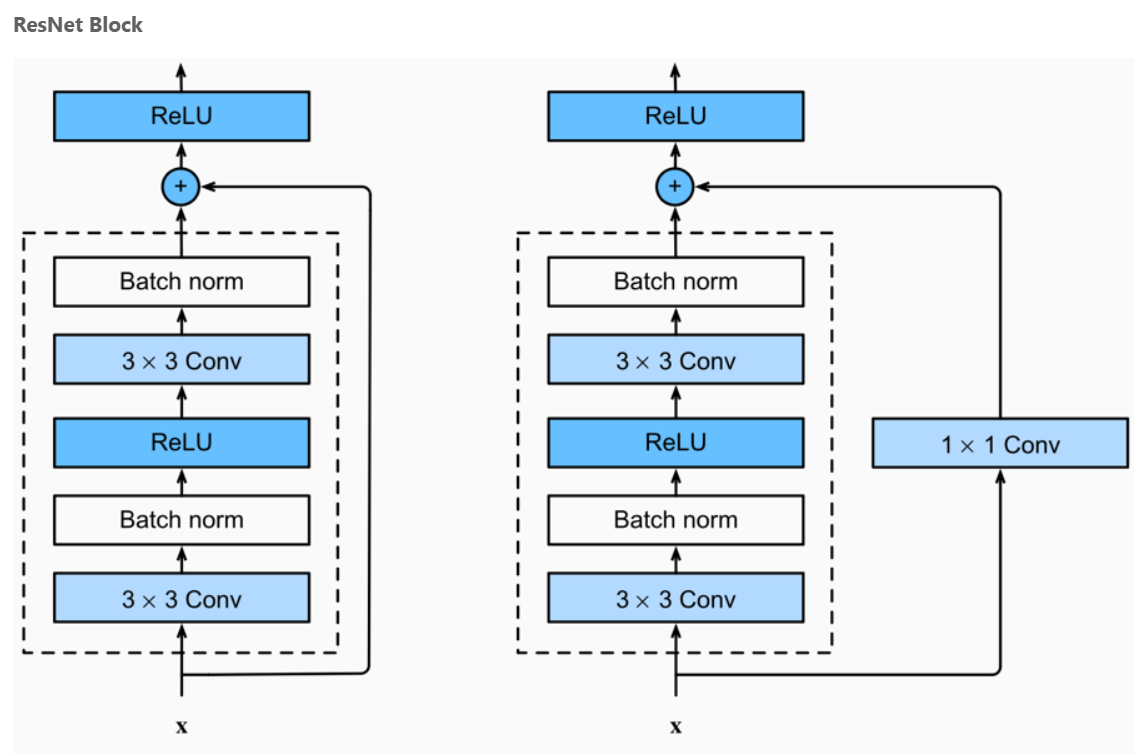

## 20. Residual block

Cộng trước, ReLU sau. Shortcut là identity khi shape khớp, là conv 1×1 + BN khi
đổi channel hoặc stride.

In [94]:
# Định nghĩa BasicBlock
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:       # cần projection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)             # cộng trước
        return torch.relu(out)                   # ReLU sau

In [95]:
# Hai trường hợp shortcut: identity và projection
ident = BasicBlock(64, 64, stride=1)
proj = BasicBlock(64, 128, stride=2)
x = torch.rand(1, 64, 56, 56)

print("identity  :", tuple(x.shape), "->", tuple(ident(x).shape),
      "| shortcut:", type(ident.shortcut).__name__)
print("projection:", tuple(x.shape), "->", tuple(proj(x).shape),
      "| shortcut:", type(proj.shortcut).__name__)
print("\ntham số một BasicBlock(64, 64, s1):", f"{n_params(ident):,}")

assert n_params(ident) == 73_984
assert ident(x).shape == (1, 64, 56, 56)
assert proj(x).shape == (1, 128, 28, 28)

identity  : (1, 64, 56, 56) -> (1, 64, 56, 56) | shortcut: Identity
projection: (1, 64, 56, 56) -> (1, 128, 28, 28) | shortcut: Sequential

tham số một BasicBlock(64, 64, s1): 73,984


In [96]:
# Vì sao phải có projection: bỏ shortcut thì phép cộng hỏng ngay khi shape đổi
f_out = torch.rand(1, 128, 28, 28)     # nhánh chính sau stride 2
x_in = torch.rand(1, 64, 56, 56)       # input chưa chỉnh
try:
    f_out + x_in
except RuntimeError as e:
    print("RuntimeError:\n ", e)

shortcut = nn.Sequential(nn.Conv2d(64, 128, 1, stride=2, bias=False),
                         nn.BatchNorm2d(128))
print("\nsau projection:", tuple(shortcut(x_in).shape), "-> cộng được")
assert (f_out + shortcut(x_in)).shape == (1, 128, 28, 28)

RuntimeError:
  The size of tensor a (28) must match the size of tensor b (56) at non-singleton dimension 3

sau projection: (1, 128, 28, 28) -> cộng được


## 21. ResNet-18 `[2, 2, 2, 2]`

In [97]:
# Định nghĩa ResNet-18 theo bốn stage
class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        # Block đầu chịu trách nhiệm đổi channel và giảm chiều
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride),
                             BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))


In [98]:
# Bảng shape và tham số qua từng stage, với ảnh vào 96x96 của Bài 3
r18 = ResNet18(num_classes=21)
x = torch.rand(1, 3, 96, 96)

print(f"{'stage':<12}{'output shape':<20}{'tham số':>12}")
x = r18.stem(x)
print(f"{'stem':<12}{str(tuple(x.shape)):<20}{n_params(r18.stem):>12,}")
for name in ("layer1", "layer2", "layer3", "layer4"):
    layer = getattr(r18, name)
    x = layer(x)
    print(f"{name:<12}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")
v = r18.pool(x).flatten(1)
print(f"{'avgpool':<12}{str(tuple(v.shape)):<20}{0:>12,}")
print(f"{'fc':<12}{str(tuple(r18.fc(v).shape)):<20}{n_params(r18.fc):>12,}")
print(f"{'TỔNG':<12}{'':<20}{n_params(r18):>12,}")

assert n_params(r18) == 11_187_285
assert tuple(x.shape) == (1, 512, 3, 3)

stage       output shape             tham số
stem        (1, 64, 24, 24)            9,536
layer1      (1, 64, 24, 24)          147,968
layer2      (1, 128, 12, 12)         525,568
layer3      (1, 256, 6, 6)         2,099,712
layer4      (1, 512, 3, 3)         8,393,728
avgpool     (1, 512)                       0
fc          (1, 21)                   10,773
TỔNG                              11,187,285


In [99]:
# Vì sao không dùng ảnh 64x64: ResNet giảm chiều 5 lần
for size in (64, 96, 112, 224):
    with torch.no_grad():
        z = r18.stem(torch.rand(1, 3, size, size))
        for name in ("layer1", "layer2", "layer3", "layer4"):
            z = getattr(r18, name)(z)
    print(f"ảnh vào {size:>3}x{size:<3} -> layer4 ra {tuple(z.shape)[1:]}")

# Nhận xét: 64x64 chỉ còn 2x2, nên chốt 96x96 hoặc 112x112

ảnh vào  64x64  -> layer4 ra (512, 2, 2)
ảnh vào  96x96  -> layer4 ra (512, 3, 3)
ảnh vào 112x112 -> layer4 ra (512, 4, 4)
ảnh vào 224x224 -> layer4 ra (512, 7, 7)


In [100]:
# Đối chiếu với bản resnet18 của torchvision
try:
    from torchvision.models import resnet18 as tv_resnet18
    tv = tv_resnet18(weights=None)
    print("torchvision resnet18, 1000 lớp:", f"{n_params(tv):,}")
    assert n_params(tv) == 11_689_512

    tv.fc = nn.Linear(512, 21)
    print("sau khi đổi fc sang 21 lớp   :", f"{n_params(tv):,}")
    assert n_params(tv) == n_params(r18) == 11_187_285
    print("Khớp với bản tự cài ở trên.")
except ImportError:
    print("Chưa có torchvision, bỏ qua bước đối chiếu.")

torchvision resnet18, 1000 lớp: 11,689,512
sau khi đổi fc sang 21 lớp   : 11,187,285
Khớp với bản tự cài ở trên.


# Phần V · Transfer learning

## 22. Backbone và classifier

Ô dưới cần mạng để tải trọng số `microsoft/resnet-50` lần đầu. Nếu không tải
được thì tự bỏ qua.

In [101]:
# Tải model pretrained và tách phần backbone
HAS_HF = False
try:
    from transformers import ResNetForImageClassification
    base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
    HAS_HF = True
except Exception as e:
    print("Không tải được pretrained model:", type(e).__name__)
    print("Bỏ qua phần V; phần còn lại của notebook vẫn chạy.")

if HAS_HF:
    backbone = base.resnet
    print("backbone:", f"{n_params(backbone):,}", "tham số")
    print("classifier gốc 1000 lớp của ImageNet -> sẽ thay bằng 21 lớp")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

backbone: 23,508,032 tham số
classifier gốc 1000 lớp của ImageNet -> sẽ thay bằng 21 lớp


In [102]:
# Định nghĩa model: backbone pretrained + classifier mới 21 lớp
class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)

        if freeze_backbone:                   # hai dòng này tạo ra feature extraction
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output    # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)     # [B, 2048]
        return self.classifier(features)                # [B, 21]
           # [B, 21]

In [103]:
# Theo dõi shape từ ảnh vào đến logits
if HAS_HF:
    model = PretrainedResnet(num_classes=21)
    x = torch.rand(2, 3, 224, 224)
    with torch.no_grad():
        feats = model.resnet(x).pooler_output
        show("ảnh vào", x)
        show("pooler_output", feats)
        show("sau squeeze", feats.squeeze(-1).squeeze(-1))
        show("logits", model(x))

    assert feats.shape == (2, 2048, 1, 1)
    assert model(x).shape == (2, 21)
    print("\n2048 = 512 x 4, hệ số nở của Bottleneck ở stage cuối")

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ảnh vào                      (2, 3, 224, 224)
pooler_output                (2, 2048, 1, 1)
sau squeeze                  (2, 2048)
logits                       (2, 21)

2048 = 512 x 4, hệ số nở của Bottleneck ở stage cuối


## 23. Feature extraction và fine-tuning

Khác nhau ở số tham số được cập nhật và ở learning rate.

In [104]:
# Khởi tạo hai chế độ và so số tham số được cập nhật
if HAS_HF:
    fe = PretrainedResnet(21, freeze_backbone=True)
    ft = PretrainedResnet(21, freeze_backbone=False)

    print(f"{'chế độ':<22}{'tổng':>14}{'được cập nhật':>16}{'lr':>8}")
    print(f"{'feature extraction':<22}{n_params(fe):>14,}"
          f"{n_params(fe, True):>16,}{'1e-3':>8}")
    print(f"{'fine-tuning':<22}{n_params(ft):>14,}"
          f"{n_params(ft, True):>16,}{'1e-4':>8}")

    assert n_params(fe) == 23_551_061
    assert n_params(fe, trainable_only=True) == 43_029     # chỉ classifier
    assert n_params(ft, trainable_only=True) == 23_551_061

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

chế độ                          tổng   được cập nhật      lr
feature extraction        23,551,061          43,029    1e-3
fine-tuning               23,551,061      23,551,061    1e-4


In [105]:
# Optimizer chỉ nhận tham số cần học
if HAS_HF:
    opt = torch.optim.Adam(
        filter(lambda p: p.requires_grad, fe.parameters()), lr=1e-3)
    n_opt = sum(p.numel() for g in opt.param_groups for p in g["params"])
    print("tham số nằm trong optimizer (feature extraction):", f"{n_opt:,}")
    assert n_opt == 43_029

tham số nằm trong optimizer (feature extraction): 43,029


In [106]:
# Lấy mean/std đi kèm model thay vì tự điền: dùng sai không báo lỗi, chỉ kém kết quả
if HAS_HF:
    try:
        from transformers import AutoImageProcessor
        proc = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
        print("mean:", proc.image_mean)
        print("std :", proc.image_std)
        print("size:", proc.size)
    except Exception as e:
        print("Không tải được processor:", type(e).__name__)
        print("Dùng mean/std của ImageNet:", MEAN, STD)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

mean: (0.485, 0.456, 0.406)
std : (0.229, 0.224, 0.225)
size: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None)


# Phụ lục · Khung huấn luyện và đánh giá

Khung dùng chung cho cả bốn bài: chỉ đổi `model`, `IMG_SIZE` và `lr`. Không có
số liệu mẫu ở đây, kết quả phải tự chạy.

In [108]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

In [110]:
# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

In [111]:
# Vòng huấn luyện: bỏ chú thích khi đã có dữ liệu

EPOCHS = 20
model = LeNet5(in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su = []
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
    va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
    lich_su.append((ep, tr_loss, va_loss))
    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")

print("Khung huấn luyện đã sẵn sàng.")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7960/0.1494   val 2.6128/0.1892


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.5541/0.2157   val 2.4126/0.2669


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18  train 1.9211/0.4012   val 2.1563/0.3436


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19  train 1.9032/0.4100   val 2.0869/0.3675


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.8726/0.4145   val 2.0749/0.3456
Khung huấn luyện đã sẵn sàng.


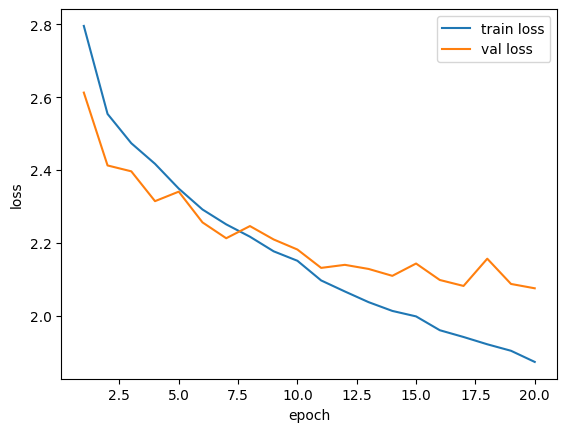

Khung vẽ đồ thị đã sẵn sàng.


In [112]:
# Vẽ loss train và val để thấy điểm hai đường tách nhau

import matplotlib.pyplot as plt
ep, tr, va = zip(*lich_su)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()
print("Khung vẽ đồ thị đã sẵn sàng.")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


                  precision    recall  f1-score   support

        banh-can     0.3600    0.2647    0.3051        34
        banh-hoi     0.5366    0.2821    0.3697        78
    banh-mi-chao     0.3016    0.3958    0.3423        48
        banh-tet     0.5294    0.5902    0.5581        61
 banh-trang-tron     0.3000    0.2885    0.2941        52
          banh-u     0.1613    0.1786    0.1695        28
        banh-uot     0.2286    0.2286    0.2286        70
       bap-nuong     0.0625    0.0667    0.0645        15
          bo-kho     0.3429    0.3077    0.3243        39
       bo-la-lot     0.5000    0.4868    0.4933        76
       bot-chien     0.1000    0.1087    0.1042        46
           ca-ri     0.2000    0.0690    0.1026        29
    canh-kho-qua     0.4468    0.4375    0.4421        48
   canh-khoai-mo     0.6667    0.6667    0.6667        30
        ga-nuong     0.3276    0.3455    0.3363        55
          goi-ga     0.3208    0.3953    0.3542        43
          ha-

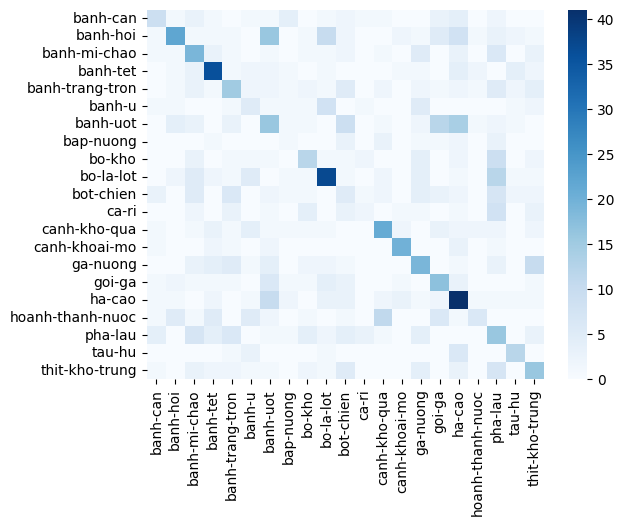

In [115]:
# Đo lường: macro-F1 là độ đo chính của cả bốn bài

from sklearn.metrics import classification_report, confusion_matrix, f1_score

_, _, y_true, y_pred = evaluate(model, val_dl, criterion, device)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("macro-F1:", f1_score(y_true, y_pred, average="macro"))

import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")

print("Khung đánh giá đã sẵn sàng.")